## Evolutionary-track fitting with NUTS

Same observations as `fit_isochrone.ipynb`, using the existing local track NPZ.
The grid covers initial mass 0.8–1.5 solar masses, initial FeH −0.25–0.25, and EEP 202–550.
Run from within this repository, with a fresh kernel for the parallel-chain configuration.

In [1]:
from pathlib import Path
import numpyro

num_chains = 4
numpyro.set_host_device_count(num_chains)  # before JAX initializes devices

import jax
jax.config.update("jax_enable_x64", True)

from jaxstar.mistfit import MistModel, MistFit

In [2]:
repo_root = next(
    p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/jaxstar").is_dir()
)
grid_path = repo_root / "benchmark-results/mist-track-grid-extended/grid.npz"

grid_path = (
    repo_root
    / "benchmark-results/mist-full-track-grid"
    / "mistgrid_tracks_v1.2_vvcrit0.4_afe0.npz"
)

model = MistModel.from_tracks(grid_path)

In [3]:
observations = {
    "teff": (5719, 110.),
    "feh": (-0.12, 0.1),
    "kmag": (8.843, 0.014),
    "parallax": (7.27355841, 3.008e-2),
}
mf = MistFit(model=model, observations=observations)

### NUTS

Mass, initial FeH and EEP bounds default to the grid limits. Age is an output;
`linear_age=True` uses the centered `dt/dEEP` field for the age prior.
EEP uses a fixed interval; the default soft upper age bound is 13.8 Gyr,
with `age_bound_width=0.1` Gyr. Set `"age_max": None` in `model_kwargs`
to disable it. `age_min` optionally adds a lower bound in Gyr.
Each bound has a log penalty of −15 at the boundary, approaching −30 outside;
it is a soft weight and also applies with `nodata=True`.


In [7]:
mcmc = mf.run_nuts(
    jax.random.PRNGKey(0),
    num_chains=num_chains,
    #model_kwargs={"linear_age": True, "nodata": True},
    model_kwargs={"linear_age": True, "age_max": 13.8},
    output_keys=("kmag_abs",),
)

  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

In [8]:
model_kwargs={
    "linear_age": True,
    "age_max": 13.8,
    "massmin": 0.8, "massmax": 1.5,
    "fmin": -0.25, "fmax": 0.25,
    "eepmin": 202., "eepmax": 550.,
}

mcmc = mf.run_nuts(
    jax.random.PRNGKey(0),
    num_chains=num_chains,
    model_kwargs=model_kwargs,
    output_keys=("kmag_abs",),
)

  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

In [8]:
mcmc.print_summary()


                mean       std    median      5.0%     95.0%     n_eff     r_hat
  distance      0.14      0.00      0.14      0.14      0.14   8449.56      1.00
       eep    402.06     19.60    407.04    374.41    426.71   1320.80      1.00
  feh_init     -0.04      0.08     -0.04     -0.16      0.10   5282.18      1.00
      mass      0.94      0.05      0.93      0.86      1.00   1594.64      1.00

Number of divergences: 0


In [9]:
idata = mf.to_inference_data(mcmc)
# Choose a new directory for each run, or pass overwrite=True explicitly.
result_dir = mf.save_result(idata, repo_root / "examples/mistfit/results/track_nuts", overwrite=True)

/Users/k_masuda/miniforge3/envs/jnkepler/lib/python3.12/site-packages/arviz/stats/diagnostics.py:596: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/Users/k_masuda/miniforge3/envs/jnkepler/lib/python3.12/site-packages/arviz/stats/diagnostics.py:991: RuntimeWarning: invalid value encountered in scalar divide
  varsd = varvar / evar / 4


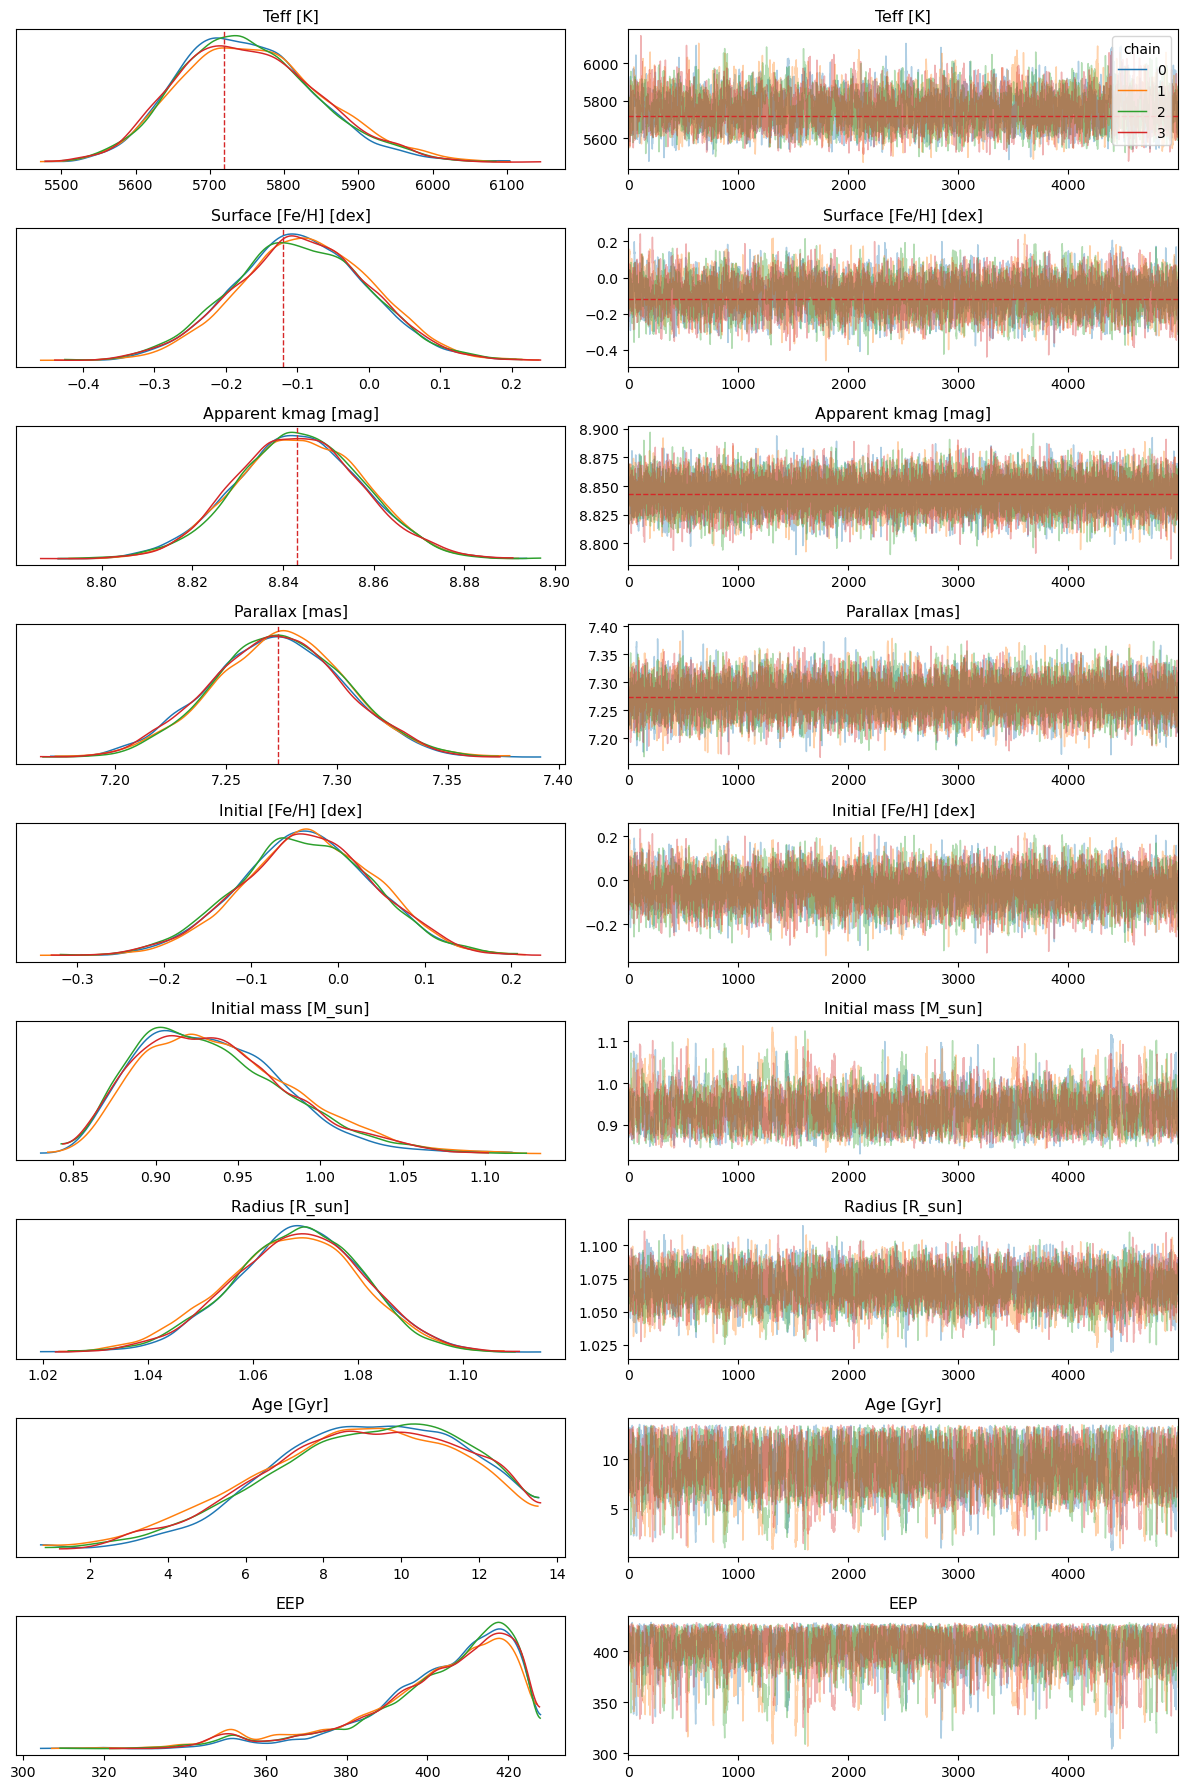

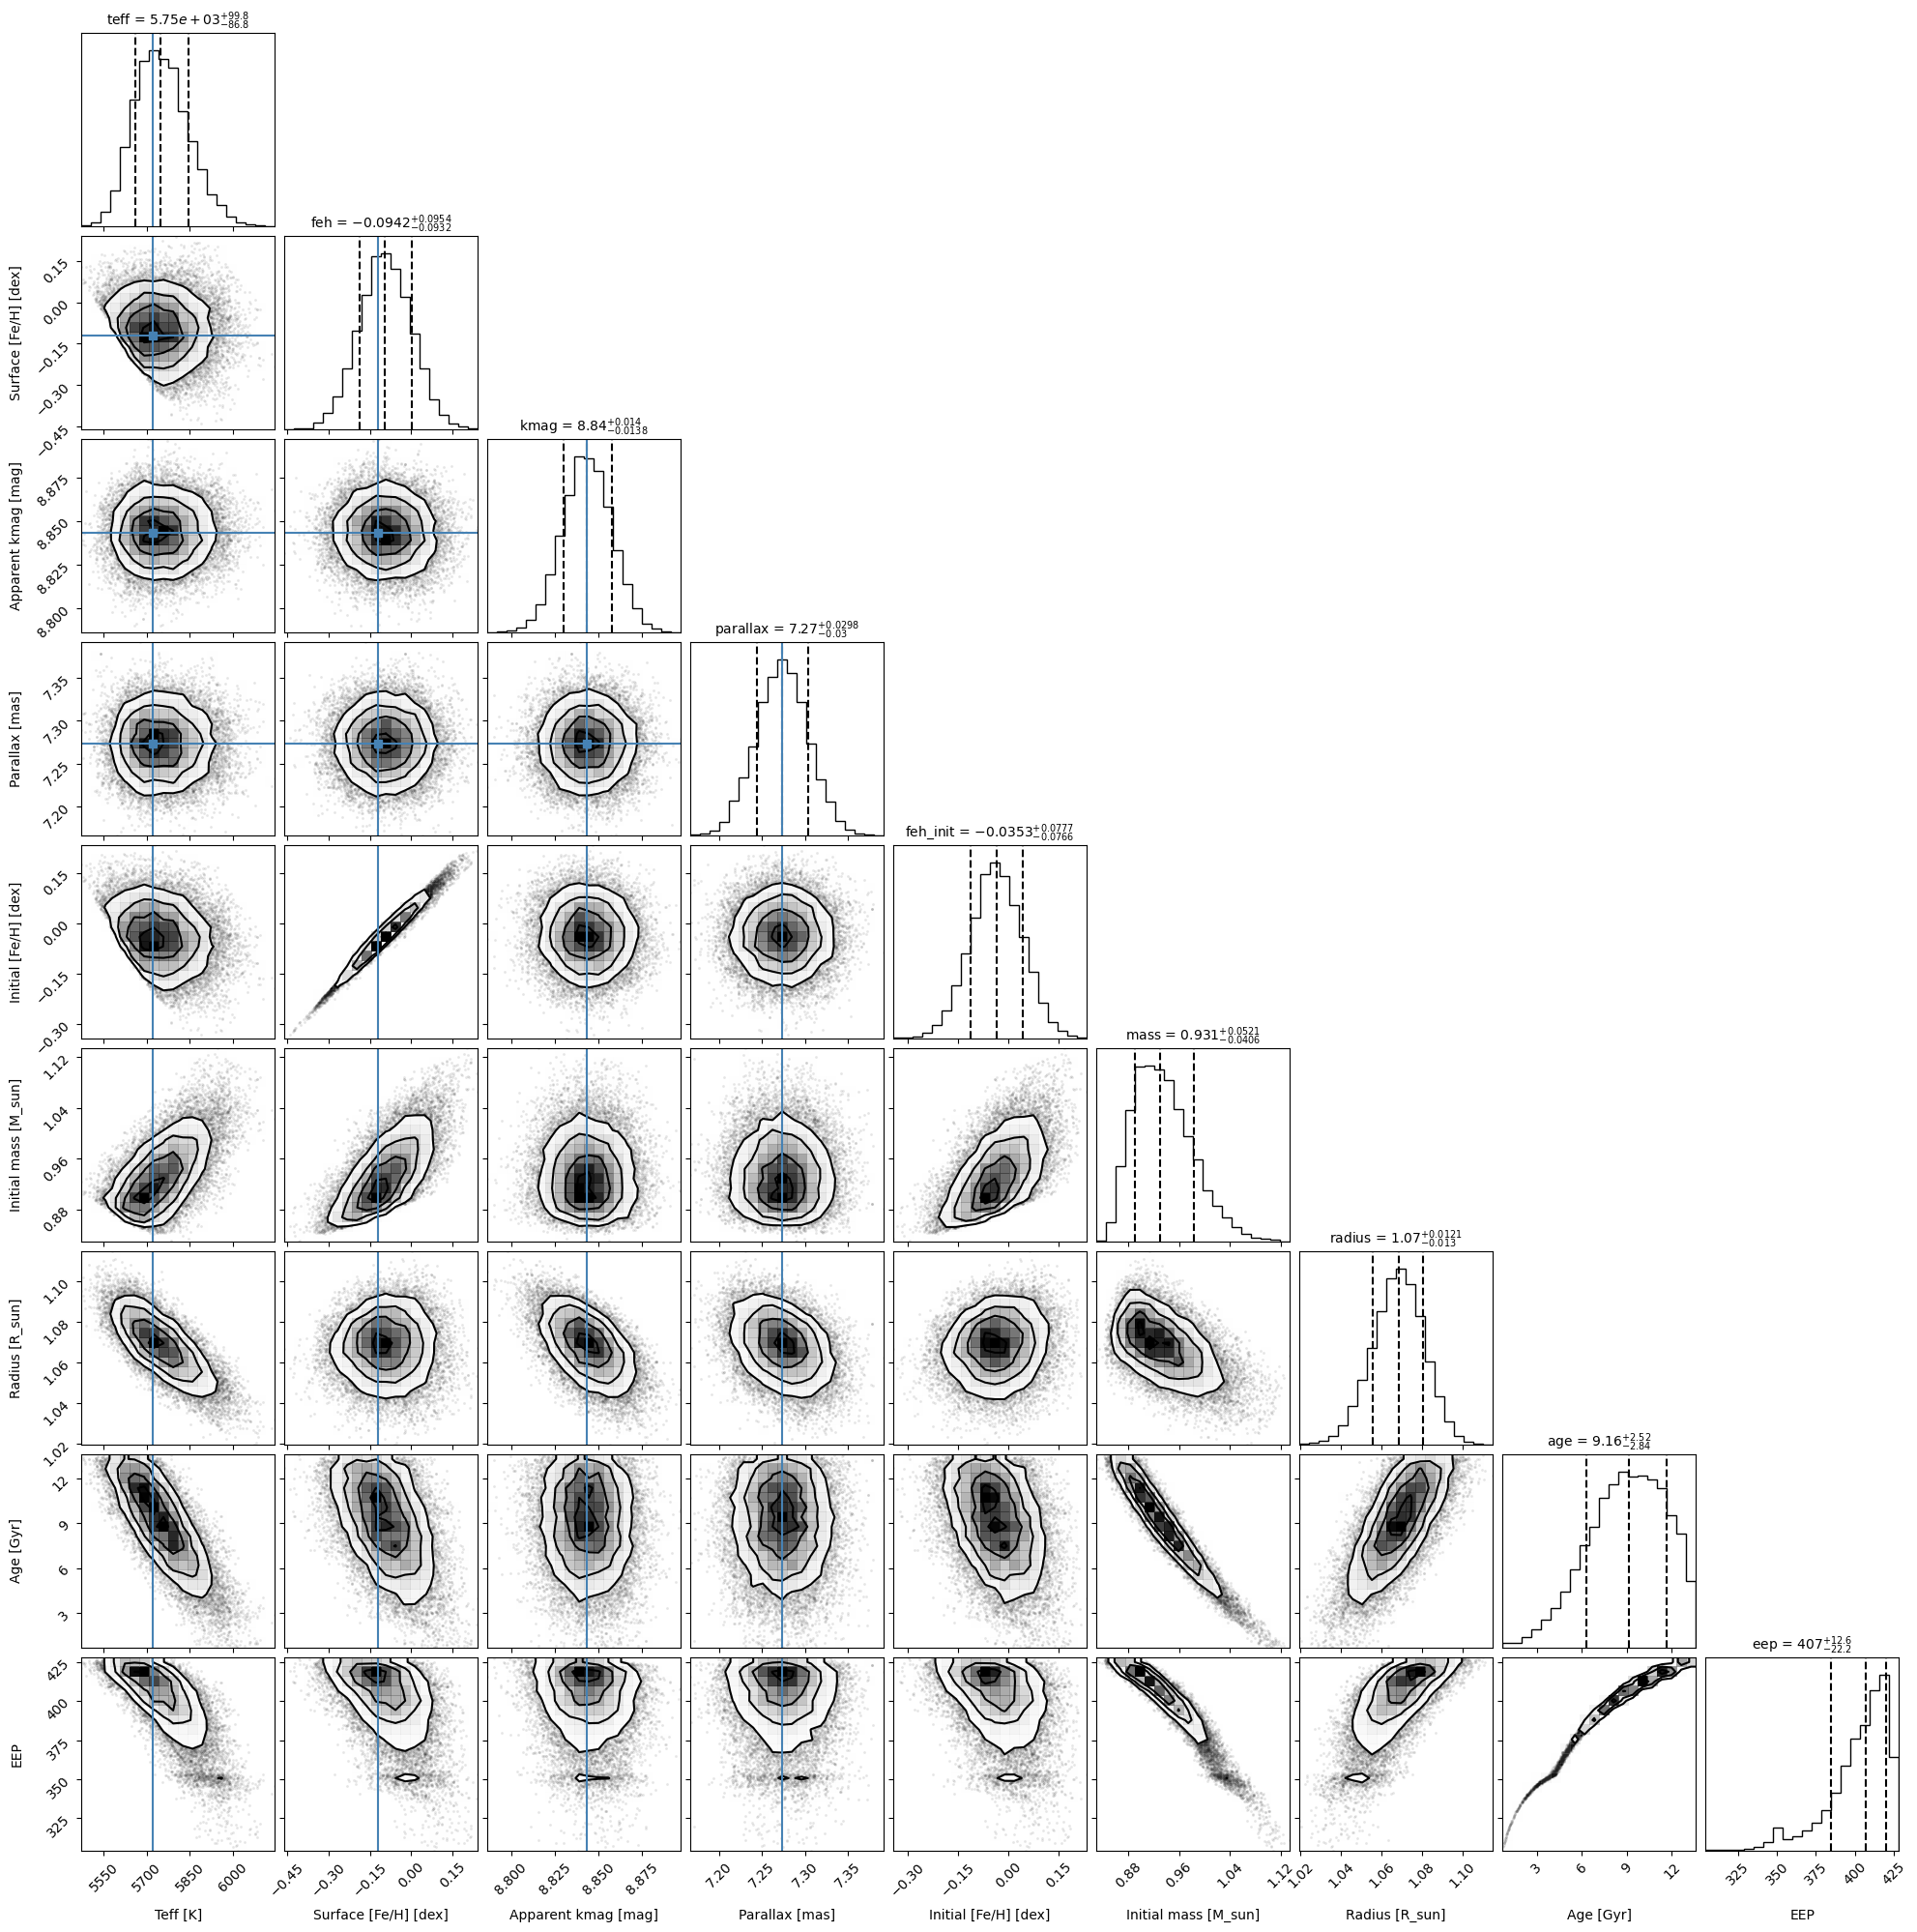

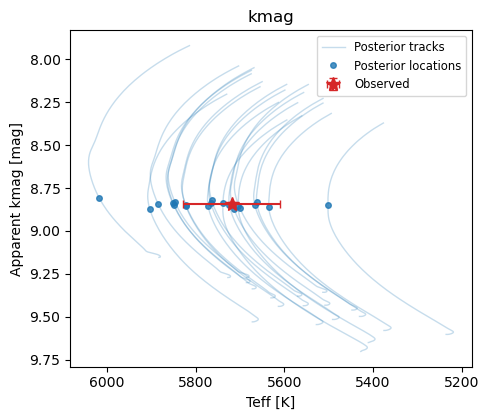

In [10]:
outkeys = [*observations, "feh_init", "mass", "radius", "age", "eep"]
figures = mf.plot_diagnostics(idata, keys=outkeys, output_dir=result_dir, overwrite=True)

## Nested sampling

In [13]:
mn_dir = "results/track_multinest"
mn = mf.run_multinest(outputfiles_basename=mn_dir + "/run1_", n_live_points=100)

 MultiNest Warning: no resume file found, starting from scratch
 *****************************************************
 MultiNest v3.10
 Copyright Farhan Feroz & Mike Hobson
 Release Jul 2015

 no. of live points =  100
 dimensionality =    4
 *****************************************************

 MultiNest Warning!
 Parameter            4  of mode            1  is converging towards the edge of the prior.

 MultiNest Warning!
 Parameter            4  of mode            1  is converging towards the edge of the prior.

 MultiNest Warning!
 Parameter            4  of mode            1  is converging towards the edge of the prior.

 MultiNest Warning!
 Parameter            4  of mode            1  is converging towards the edge of the prior.

 MultiNest Warning!
 Parameter            4  of mode            1  is converging towards the edge of the prior.

 MultiNest Warning!
 Parameter            4  of mode            1  is converging towards the edge of the prior.

 MultiNest Warning!
 Pa

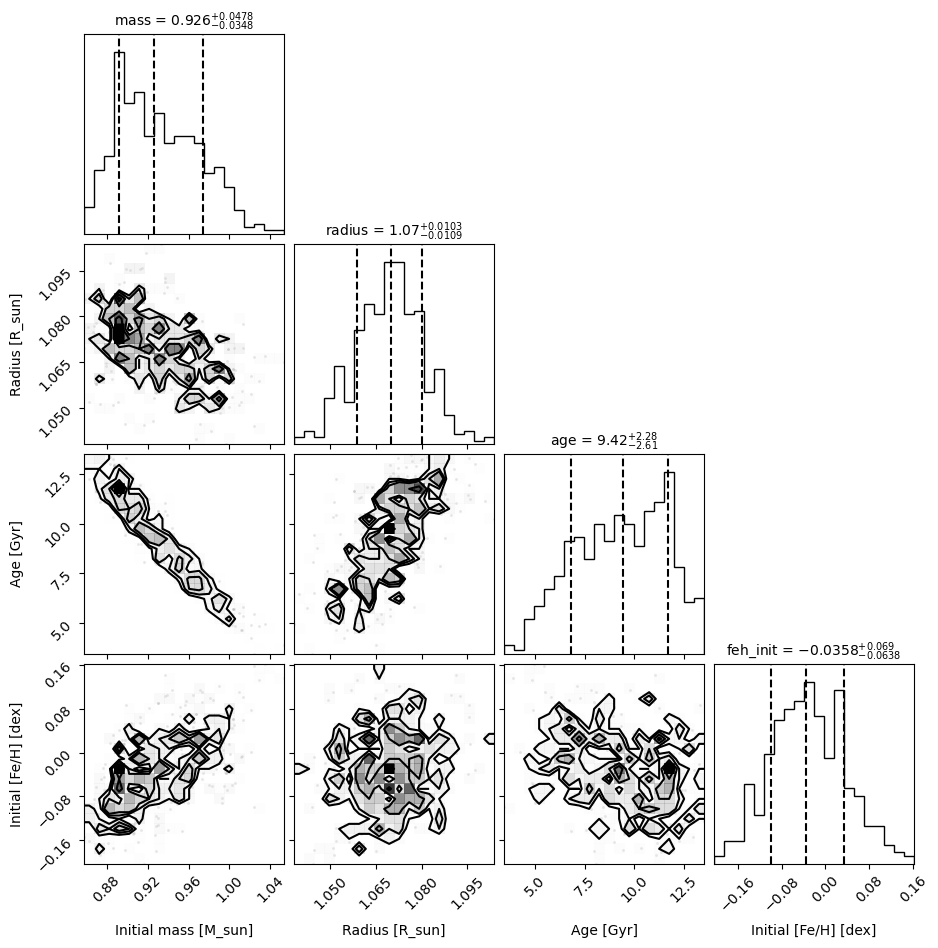

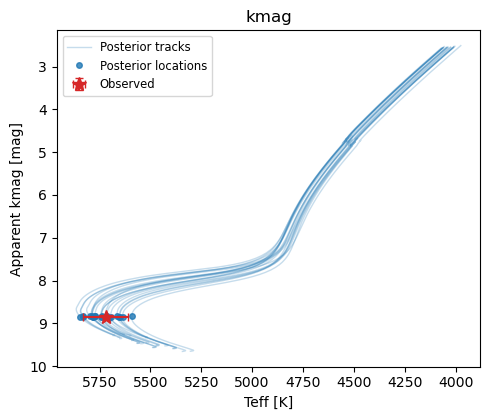

In [15]:
mn_idata = mf.to_inference_data(mn)
mf.save_result(mn_idata, mn_dir, overwrite=True)
mn_figures = mf.plot_diagnostics(mn_idata, output_dir=mn_dir,
                                keys=("mass", "radius", "age", "feh_init"),
                                overwrite=True)

In [16]:
from jaxstar.mistfit import get_run_metadata
get_run_metadata(mn_idata)["evidence"]

{'logZ': -20.15663047160921, 'logZerr': 0.42100114063399846}